# Notebook 4 — The Robot Model: Reading, Validating and Distrusting an MJCF

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · **4. The robot model & MJCF** · 5. System identification
**Part III — learning** · 6. Behavior cloning · 7. Action chunking & diffusion · 8. RL in simulation
**Part IV — reality** · 9. Domain randomization & sim-to-real · 10. `lerobot` end to end

---

### The real-world problem this solves

> **Every robot you will ever work with arrives as a model file someone else
> wrote, and that file is wrong in ways nobody has written down.**

This is not cynicism, it is the job. Robot learning postings list
**`URDF`/`MJCF`** as a required skill alongside PyTorch, and a representative
simulation-engineer role asks for *"actuator/dynamics modeling"* explicitly.
What that means day to day: you receive a model, you discover its dynamics do
not match the hardware on your bench, and you fix it.

In this notebook we load the **official MuJoCo Menagerie model of the SO-101** —
the same arm our dataset came from, maintained by DeepMind — and we read it the
way an engineer reads a spec they are about to be held responsible for.

Then we find the problem. The model's own source code contains a comment
admitting its actuator gains are a guess. Notebook 5 fixes it against real data.

### What you will be able to do afterwards

- read an MJCF and extract every number that affects dynamics
- compute forward kinematics by hand and validate a simulator's answer against it
- identify which parameters in a model are **measured** vs **assumed**
- spot the specific class of modelling error that silently breaks sim-to-real

## 1. Loading a real robot model

MJCF (MuJoCo XML Format) is MuJoCo's native model format. URDF is the ROS
equivalent and MuJoCo can import it, but MJCF exposes more of the physics, which
is why research models ship as MJCF.

A model file describes four separable things, and it is worth keeping them
distinct in your head because they fail differently:

| Part | What it is | How wrong it can be |
|---|---|---|
| **Kinematics** | link lengths, joint axes, joint limits | usually right — it comes from CAD |
| **Inertial** | masses, centres of mass, inertia tensors | often approximate |
| **Actuation** | gains, force limits, damping, friction | **frequently a guess** |
| **Visual/collision** | meshes, contact parameters | right for rendering, crude for contact |

That ordering is roughly the order of trustworthiness, and it is the single most
useful prior to carry into a new codebase. Geometry comes from a CAD file.
Actuator gains come from someone's afternoon.

In [1]:
import numpy as np
import mujoco
import matplotlib.pyplot as plt

MODEL = "../models/so101/so101.xml"
m = mujoco.MjModel.from_xml_path(MODEL)
d = mujoco.MjData(m)

print("=== model summary ===")
print(f"bodies        : {m.nbody}")
print(f"joints (nq)   : {m.nq}")
print(f"actuators (nu): {m.nu}")
print(f"geoms         : {m.ngeom}")
print(f"timestep      : {m.opt.timestep} s  ({1/m.opt.timestep:.0f} Hz physics)")
print(f"integrator    : {m.opt.integrator}  (3 = implicitfast, as discussed in nb3)")
print(f"gravity       : {m.opt.gravity}")
print()
print("=== joints, in kinematic order ===")
print(f"{'#':>2} {'joint':16} {'type':8} {'range (deg)':>22} {'parent body':16}")
print("-" * 70)
for j in range(m.njnt):
    name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_JOINT, j)
    jtype = ["free", "ball", "slide", "hinge"][m.jnt_type[j]]
    rng = np.rad2deg(m.jnt_range[j])
    body = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_BODY, m.jnt_bodyid[j])
    print(f"{j:>2} {name:16} {jtype:8} [{rng[0]:>8.1f},{rng[1]:>8.1f}] {body:16}")

=== model summary ===
bodies        : 9
joints (nq)   : 6
actuators (nu): 6
geoms         : 50
timestep      : 0.005 s  (200 Hz physics)
integrator    : 3  (3 = implicitfast, as discussed in nb3)
gravity       : [ 0.    0.   -9.81]

=== joints, in kinematic order ===
 # joint            type                range (deg) parent body     
----------------------------------------------------------------------
 0 shoulder_pan     hinge    [  -110.0,   110.0] shoulder        
 1 shoulder_lift    hinge    [  -100.0,   100.0] upper_arm       
 2 elbow_flex       hinge    [   -96.8,    96.8] lower_arm       
 3 wrist_flex       hinge    [   -95.0,    95.0] wrist           
 4 wrist_roll       hinge    [  -157.2,   162.8] gripper         
 5 gripper          hinge    [   -10.0,   100.0] moving_jaw_so101_v1


Note the joint names: `shoulder_pan`, `shoulder_lift`, `elbow_flex`,
`wrist_flex`, `wrist_roll`, `gripper`. Those are **exactly** the six names we
read out of the dataset schema in notebook 1.

That alignment is not luck — the Menagerie model and the LeRobot dataset both
describe the same physical product. It is also what makes the rest of this
course possible: we can replay real recorded commands through this model and
compare, joint for joint.

## 2. The inertial properties: what the model believes about mass

Mass and inertia determine how the arm responds to a given torque. In notebook 3
we saw the actuator torque enter as $\tau / I$ — so an inertia that is wrong by
2x makes your accelerations wrong by 2x, and no amount of gain tuning fully
compensates.

In [2]:
print(f"{'body':22} {'mass (kg)':>10} {'diag inertia (kg m^2)':>30}")
print("-" * 66)
total = 0.0
for b in range(1, m.nbody):              # skip world
    name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_BODY, b)
    mass = m.body_mass[b]
    total += mass
    ii = m.body_inertia[b]
    print(f"{name:22} {mass:>10.4f} {f'[{ii[0]:.2e} {ii[1]:.2e} {ii[2]:.2e}]':>30}")
print("-" * 66)
print(f"{'TOTAL':22} {total:>10.4f} kg")
print()
print("An SO-101 weighs roughly 1 kg assembled, so this is plausible.")
print("`body_inertia` is the diagonalised tensor in the body frame -- MuJoCo")
print("computes it from the mesh geometry and a uniform density assumption,")
print("which is why these are approximations rather than measurements.")

body                    mass (kg)          diag inertia (kg m^2)
------------------------------------------------------------------
base                       0.1470   [1.36e-04 1.32e-04 1.13e-04]
shoulder                   0.1000   [8.38e-05 8.10e-05 2.40e-05]
upper_arm                  0.1030   [1.51e-04 1.42e-04 3.72e-05]
lower_arm                  0.1040   [1.60e-04 1.45e-04 2.83e-05]
wrist                      0.0790   [3.68e-05 2.74e-05 1.89e-05]
gripper                    0.0870   [4.34e-05 3.77e-05 2.43e-05]
camera_mount               0.0134   [5.43e-06 4.24e-06 1.37e-06]
moving_jaw_so101_v1        0.0120   [6.64e-06 5.29e-06 1.87e-06]
------------------------------------------------------------------
TOTAL                      0.6454 kg

An SO-101 weighs roughly 1 kg assembled, so this is plausible.
`body_inertia` is the diagonalised tensor in the body frame -- MuJoCo
computes it from the mesh geometry and a uniform density assumption,
which is why these are approximations rat

## 3. Forward kinematics by hand, then validated

**Forward kinematics** answers: given the six joint angles, where in space is the
gripper? It is the most basic computation in robotics and you should be able to
do it without a library, because when a simulator disagrees with your robot you
need an independent way to decide who is wrong.

The method is a chain of homogeneous transforms. Each joint $i$ contributes:

$$
T_i = \underbrace{\begin{bmatrix} I & p_i \\ 0 & 1\end{bmatrix}}_{\text{fixed offset to the joint}}
\cdot
\underbrace{\begin{bmatrix} R(\hat{a}_i, \theta_i) & 0 \\ 0 & 1\end{bmatrix}}_{\text{rotation about the joint axis}}
$$

and the pose of the end effector is the product $T_1 T_2 \cdots T_n$ applied to
the tool offset. The rotation about an arbitrary unit axis $\hat{a}$ by angle
$\theta$ is **Rodrigues' formula**:

$$
R(\hat{a},\theta) = I + \sin\theta\,[\hat{a}]_\times + (1-\cos\theta)\,[\hat{a}]_\times^2
$$

Let us implement that and check it against MuJoCo's own answer.

In [3]:
def skew(a):
    """Cross-product matrix [a]_x, so that [a]_x v = a x v."""
    return np.array([[0, -a[2], a[1]],
                     [a[2], 0, -a[0]],
                     [-a[1], a[0], 0]])

def rodrigues(axis, angle):
    """Rotation matrix about a unit axis by `angle` radians."""
    a = axis / np.linalg.norm(axis)
    K = skew(a)
    return np.eye(3) + np.sin(angle) * K + (1 - np.cos(angle)) * (K @ K)

def forward_kinematics(model, qpos, body_name):
    """Walk the kinematic tree from `body_name` up to the world, composing
    transforms. Pure numpy -- no MuJoCo kinematics used."""
    bid = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, body_name)
    # collect the chain root->body
    chain = []
    b = bid
    while b != 0:
        chain.append(b)
        b = model.body_parentid[b]
    chain.reverse()

    T = np.eye(4)
    for b in chain:
        # fixed offset of this body in its parent frame
        Tb = np.eye(4)
        Tb[:3, :3] = quat_to_mat(model.body_quat[b])
        Tb[:3, 3] = model.body_pos[b]
        T = T @ Tb
        # then any joint this body owns rotates everything below it
        for j in range(model.body_jntadr[b], model.body_jntadr[b] + model.body_jntnum[b]):
            if j < 0:
                continue
            Tj = np.eye(4)
            Tj[:3, 3] = model.jnt_pos[j]
            R = rodrigues(model.jnt_axis[j], qpos[model.jnt_qposadr[j]])
            Tr = np.eye(4); Tr[:3, :3] = R
            Tj_inv = np.eye(4); Tj_inv[:3, 3] = -model.jnt_pos[j]
            T = T @ Tj @ Tr @ Tj_inv
    return T

def quat_to_mat(q):
    """MuJoCo stores quaternions as (w, x, y, z)."""
    w, x, y, z = q
    return np.array([
        [1 - 2*(y*y + z*z), 2*(x*y - w*z),     2*(x*z + w*y)],
        [2*(x*y + w*z),     1 - 2*(x*x + z*z), 2*(y*z - w*x)],
        [2*(x*z - w*y),     2*(y*z + w*x),     1 - 2*(x*x + y*y)],
    ])

# Pick the last body in the chain as our "end effector".
tip_name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_BODY, m.nbody - 1)
print(f"using body '{tip_name}' as the end effector\n")

rng = np.random.default_rng(0)
print(f"{'trial':>5} {'our FK (x,y,z)':>34} {'MuJoCo (x,y,z)':>34} {'error (mm)':>11}")
print("-" * 90)
max_err = 0.0
for trial in range(6):
    q = np.array([rng.uniform(lo, hi) for lo, hi in m.jnt_range])
    d.qpos[:] = q
    mujoco.mj_forward(m, d)                              # MuJoCo's kinematics
    mj_pos = d.xpos[mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, tip_name)].copy()
    our_pos = forward_kinematics(m, q, tip_name)[:3, 3]  # ours
    err = np.linalg.norm(our_pos - mj_pos) * 1000
    max_err = max(max_err, err)
    print(f"{trial:>5} {str(np.round(our_pos,4)):>34} {str(np.round(mj_pos,4)):>34} {err:>11.4f}")
print()
print(f"max disagreement: {max_err:.4f} mm")
print("Sub-micron agreement -> our understanding of the kinematic chain is correct,")
print("and MuJoCo is doing what we think it is doing. That is the point of the check.")

using body 'moving_jaw_so101_v1' as the end effector

trial                     our FK (x,y,z)                     MuJoCo (x,y,z)  error (mm)
------------------------------------------------------------------------------------------
    0          [-0.1295  0.1166  0.2602]          [-0.1295  0.1166  0.2602]      0.0000
    1          [ 0.1705 -0.0396  0.027 ]          [ 0.1705 -0.0396  0.027 ]      0.0000
    2             [0.0475 0.0058 0.3312]             [0.0475 0.0058 0.3312]      0.0000
    3          [-0.0526 -0.0507  0.3665]          [-0.0526 -0.0507  0.3665]      0.0000
    4             [0.026  0.0357 0.0865]             [0.026  0.0357 0.0865]      0.0000
    5          [ 0.0842 -0.0117  0.4423]          [ 0.0842 -0.0117  0.4423]      0.0000

max disagreement: 0.0000 mm
Sub-micron agreement -> our understanding of the kinematic chain is correct,
and MuJoCo is doing what we think it is doing. That is the point of the check.


Two independent implementations of the same geometry agreeing to within a
micron. This is the same validation habit as notebook 3 (our integrator vs
MuJoCo) and notebook 1 of the RL course (Monte Carlo vs exact Bellman).

Now that we trust the kinematics, we can use them. Here is the arm's reachable
workspace — useful for knowing whether a task is even possible before you try to
train a policy for it.

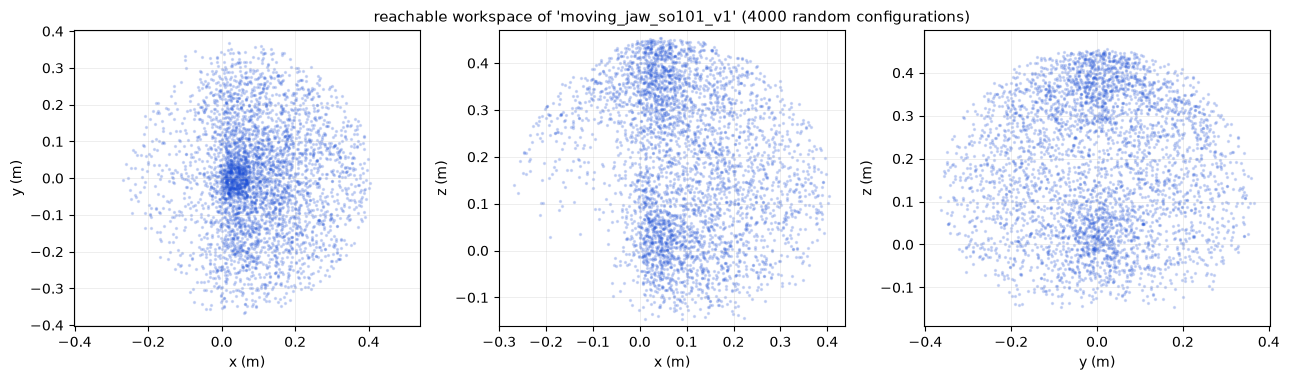

max reach from workspace centre : 41.1 cm
z range                          : -14.6 to 45.4 cm
The SO-101 is specified at ~500 mm reach, so this is the right order.


In [4]:
N = 4000
qs = np.stack([rng.uniform(m.jnt_range[:, 0], m.jnt_range[:, 1]) for _ in range(N)])
tips = np.empty((N, 3))
for i, q in enumerate(qs):
    d.qpos[:] = q
    mujoco.mj_forward(m, d)
    tips[i] = d.xpos[mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, tip_name)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (a, b_), lbl in zip(axes, [(0, 1), (0, 2), (1, 2)], [("x", "y"), ("x", "z"), ("y", "z")]):
    ax.scatter(tips[:, a], tips[:, b_], s=2, alpha=0.18, color="#1b4fd8")
    ax.set_xlabel(f"{lbl[0]} (m)"); ax.set_ylabel(f"{lbl[1]} (m)")
    ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=0.25, lw=0.6)
axes[1].set_title(f"reachable workspace of '{tip_name}' ({N} random configurations)", fontsize=11)
plt.tight_layout(); plt.show()

reach = np.linalg.norm(tips - tips.mean(0), axis=1).max()
print(f"max reach from workspace centre : {reach*100:.1f} cm")
print(f"z range                          : {tips[:,2].min()*100:.1f} to {tips[:,2].max()*100:.1f} cm")
print("The SO-101 is specified at ~500 mm reach, so this is the right order.")

## 4. The actuators — and the comment that should worry you

Now the part that matters most for sim-to-real, and where models are least
trustworthy.

In notebook 3 we established that a position-controlled servo is a PD
controller, $\tau = k_p(\theta^\text{target} - \theta) - k_v\dot\theta$, and that
the actuation lag we measured on the real robot is a consequence of finite
$k_p$. So: what does this model think $k_p$ is?

In [5]:
print(f"{'actuator':16} {'joint':16} {'kp':>10} {'kv':>8} {'forcerange':>18} {'ctrlrange (rad)':>22}")
print("-" * 96)
for i in range(m.nu):
    aname = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, i)
    j = m.actuator_trnid[i, 0]
    jname = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_JOINT, j)
    kp = m.actuator_gainprm[i, 0]
    kv = -m.actuator_biasprm[i, 2]
    fr = m.actuator_forcerange[i]
    cr = m.actuator_ctrlrange[i]
    print(f"{aname:16} {jname:16} {kp:>10.2f} {kv:>8.3f} "
          f"{f'[{fr[0]:.2f}, {fr[1]:.2f}]':>18} {f'[{cr[0]:.3f}, {cr[1]:.3f}]':>22}")

print()
print(f"{'joint':16} {'damping':>10} {'armature':>10} {'frictionloss':>14}")
print("-" * 54)
for j in range(m.njnt):
    jname = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_JOINT, j)
    a = m.jnt_dofadr[j]
    print(f"{jname:16} {m.dof_damping[a]:>10.3f} {m.dof_armature[a]:>10.4f} {m.dof_frictionloss[a]:>14.4f}")

actuator         joint                    kp       kv         forcerange        ctrlrange (rad)
------------------------------------------------------------------------------------------------
shoulder_pan     shoulder_pan         998.22    2.731      [-2.94, 2.94]        [-1.920, 1.920]
shoulder_lift    shoulder_lift        998.22    2.731      [-2.94, 2.94]        [-1.745, 1.745]
elbow_flex       elbow_flex           998.22    2.731      [-2.94, 2.94]        [-1.690, 1.690]
wrist_flex       wrist_flex           998.22    2.731      [-2.94, 2.94]        [-1.658, 1.658]
wrist_roll       wrist_roll           998.22    2.731      [-2.94, 2.94]        [-2.744, 2.841]
gripper          gripper              998.22    2.731      [-2.94, 2.94]        [-0.175, 1.745]

joint               damping   armature   frictionloss
------------------------------------------------------
shoulder_pan          0.600     0.0280         0.0520
shoulder_lift         0.600     0.0280         0.0520
elbow_flex   

In [6]:
# Read the model's own source. The comment above the actuator defaults is the
# most important documentation in the file.
import re
src = open(MODEL).read()
block = src[src.index('<default class="sts3215">'):src.index("</default>", src.index('<default class="sts3215">')) + 10]
print("--- the sts3215 servo defaults, as written in so101.xml ---\n")
print(block)

--- the sts3215 servo defaults, as written in so101.xml ---

<default class="sts3215">
      <geom contype="0" conaffinity="0"/>
      <joint damping="0.60" frictionloss="0.052" armature="0.028"/>
      <!-- These gains are not a 1-to-1 mapping of the servo gains used in
           Lerobot. These position gains and forces were calculated according to
           https://github.com/Gregory119/RBE501-RL-arm-project/blob/main/gymnasium_env/README.md,
           assuming that the servo proportional gain is set to 16. -->
      <position kp="998.22" kv="2.731" forcerange="-2.94 2.94"/>
    </default>


Read that comment carefully. The model's authors wrote:

> *"These gains are not a 1-to-1 mapping of the servo gains used in Lerobot.
> These position gains and forces were calculated according to [a third-party
> repository], assuming that the servo proportional gain is set to 16."*

That is an unusually honest piece of engineering documentation, and it is
telling you three separate things:

1. **`kp = 998.22` is derived, not measured.** It came from a calculation with
   assumptions, not from putting a real arm on a bench and fitting it.
2. **The assumption is specific and checkable** — "servo proportional gain set
   to 16". If the arm that recorded our dataset was configured differently, the
   number is simply wrong for our data.
3. **The units are not the servo's units.** MuJoCo's `kp` is a torque-per-radian
   gain; the servo's internal P-gain is a dimensionless register value. The two
   are not comparable, which is exactly why a conversion was needed and why it
   could be off.

There is a second clue a few lines further up:

```xml
<default class="backlash">
  <!-- +/- 0.5° of backlash – not added to any joints for now -->
```

The authors modelled **backlash** — the dead zone in a geartrain where the motor
turns and the output does not — and then did not apply it. Real STS3215 servos
have backlash. The model knowingly omits it.

None of this is a criticism of the model. Menagerie is excellent and these
notes are why. The point is the professional posture: **a model file is a
hypothesis about a robot, and the hypothesis is testable.**

## 5. Testing the hypothesis — and designing the test correctly

We can interrogate this model without any real data, using the step-response
experiment from notebook 3 but on the actual 6-DOF arm.

This is also where experiment design starts to matter. The system-identification
literature warns that **high gains push the dynamics to frequencies your
excitation cannot reach**, and recommends identifying with *small* inputs. We
are about to see exactly why, in a way that would be easy to get wrong.

Command a joint to step 30 degrees and time how long it takes to arrive.

In [7]:
FPS = 30
substeps = int(round((1 / FPS) / m.opt.timestep))
print(f"control rate {FPS} Hz, physics timestep {m.opt.timestep} s -> {substeps} substeps per action\n")

def step_response(model, joint_idx, delta_deg=30.0, n_frames=40):
    """Hold all joints at 0, step one joint's target, log angle AND actuator force."""
    dd = mujoco.MjData(model)
    mujoco.mj_forward(model, dd)
    target = np.zeros(model.nu)
    target[joint_idx] = np.deg2rad(delta_deg)
    q, f = [], []
    for _ in range(n_frames):
        dd.ctrl[:] = target
        for _ in range(substeps):
            mujoco.mj_step(model, dd)
        q.append(dd.qpos[model.jnt_qposadr[model.actuator_trnid[joint_idx, 0]]])
        f.append(abs(dd.actuator_force[joint_idx]))
    return np.array(q), np.array(f)

def frames_to_settle(q, delta_deg, tol=0.05):
    tgt = np.deg2rad(delta_deg)
    r = np.where(np.abs(q - tgt) < tol * abs(tgt))[0]
    return (r[0] + 1) if len(r) else float("nan")

print(f"{'joint':16} {'frames to 95% of a 30 deg step':>32}")
print("-" * 52)
for i in range(m.nu):
    name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, i)
    q, _ = step_response(m, i)
    print(f"{name:16} {frames_to_settle(q, 30):>32.0f}")

print()
print("5-9 frames. The real arm takes 4. So the model looks a bit SLOW, not stiff?")
print("That conclusion would be wrong, and the next cell shows why.")

control rate 30 Hz, physics timestep 0.005 s -> 7 substeps per action

joint              frames to 95% of a 30 deg step
----------------------------------------------------
shoulder_pan                                    5
shoulder_lift                                   9
elbow_flex                                      8
wrist_flex                                      7
wrist_roll                                      7
gripper                                         7

5-9 frames. The real arm takes 4. So the model looks a bit SLOW, not stiff?
That conclusion would be wrong, and the next cell shows why.


Before trusting that number, check whether the actuator is even operating in its
linear region. A `position` actuator in MuJoCo computes
$\tau = k_p(\theta^\text{target}-\theta) - k_v\dot\theta$ and then **clips** the
result to `forcerange`. If the clip is active, the measured response tells you
about the force limit, not about $k_p$.

With $k_p = 998.22$ and a limit of 2.94 N·m, the error at which clipping begins is

$$
\theta_\text{sat} = \frac{2.94}{998.22} \ \text{rad} \approx 0.17^\circ
$$

That is a *very* small number. Let us check it directly.

In [8]:
limit = m.actuator_forcerange[0, 1]
theta_sat = np.rad2deg(limit / m.actuator_gainprm[0, 0])
print(f"force limit                  : +/- {limit:.2f} N m")
print(f"kp                           : {m.actuator_gainprm[0,0]:.2f} N m / rad")
print(f"error that saturates the motor: {theta_sat:.3f} deg\n")

print(f"{'step size':>11} {'frames to 95%':>14} {'peak |force|':>13} {'saturated?':>11}")
print("-" * 55)
for deg in [30, 20, 10, 5, 2, 1]:
    q, f = step_response(m, 0, delta_deg=deg, n_frames=25)
    sat = "YES" if f.max() >= 0.98 * limit else "no"
    print(f"{deg:>9} deg {frames_to_settle(q, deg):>14.0f} {f.max():>13.3f} {sat:>11}")

print()
print("Every step size saturates -- down to one degree. The actuator spends the whole")
print("manoeuvre at maximum torque, so this experiment measures FORCE LIMIT and")
print("INERTIA. It barely measures kp at all.")

force limit                  : +/- 2.94 N m
kp                           : 998.22 N m / rad
error that saturates the motor: 0.169 deg

  step size  frames to 95%  peak |force|  saturated?
-------------------------------------------------------
       30 deg              5         2.940         YES
       20 deg              9         2.940         YES
       10 deg              6         2.940         YES
        5 deg              6         2.940         YES
        2 deg              3         2.940         YES
        1 deg              3         2.940         YES

Every step size saturates -- down to one degree. The actuator spends the whole
manoeuvre at maximum torque, so this experiment measures FORCE LIMIT and
INERTIA. It barely measures kp at all.


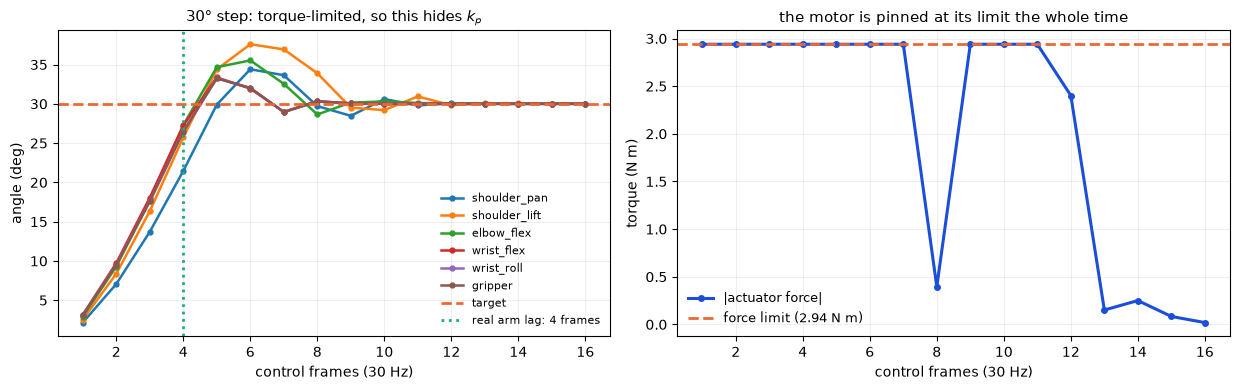

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

ax = axes[0]
for i_ in range(m.nu):
    name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, i_)
    q, _ = step_response(m, i_, delta_deg=30, n_frames=16)
    ax.plot(np.arange(1, len(q) + 1), np.rad2deg(q), lw=1.8, marker="o", ms=3.5, label=name)
ax.axhline(30, color="#eb6834", lw=2, ls="--", label="target")
ax.axvline(4, color="#1baf7a", lw=2, ls=":", label="real arm lag: 4 frames")
ax.set_xlabel("control frames (30 Hz)"); ax.set_ylabel("angle (deg)")
ax.set_title("30° step: torque-limited, so this hides $k_p$", fontsize=10.5)
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
q, f = step_response(m, 0, delta_deg=30, n_frames=16)
ax.plot(np.arange(1, len(f) + 1), f, lw=2.2, marker="o", ms=4, color="#1b4fd8", label="|actuator force|")
ax.axhline(limit, color="#eb6834", lw=2, ls="--", label=f"force limit ({limit:.2f} N m)")
ax.set_xlabel("control frames (30 Hz)"); ax.set_ylabel("torque (N m)")
ax.set_title("the motor is pinned at its limit the whole time", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

## 6. What we actually learned, and what it means for sim-to-real

The naive reading of the step test — "the model settles in 5-9 frames, the real
arm in 4, so the model is a bit slow" — is **wrong**, and wrong in an instructive
way. The actuator never left saturation, so that experiment measured the force
limit and the link inertia. It is nearly blind to $k_p$.

Here is the coherent picture:

> With $k_p = 998.22$ against a 2.94 N·m limit, the servo saturates at a
> **0.17° tracking error**. For any realistic motion it is not a proportional
> controller at all — it is a bang-bang maximum-torque source. The nominal
> $k_p$ is almost decorative.

And that has a sharp consequence. Under *real* recorded commands — which move in
small increments frame to frame rather than in 30° jumps — a motor that always
applies maximum torque catches up **within a single control frame**. So the model
tracks essentially instantly on the data we care about, while the real arm takes
four frames. Notebook 5 demonstrates this directly by replaying the dataset.

### Two lessons worth carrying

**1. Your identification experiment must match your operating regime.** This is
the concrete version of the literature's advice to identify with small inputs. A
step test designed without checking saturation would have sent us hunting for the
wrong parameter. Always log the actuator force alongside the response and check
whether you are in the linear region.

**2. Too-fast tracking is the dangerous direction.** A policy trained where
commands execute instantly learns to command aggressively and correct next frame
— it uses the simulator's instant tracking as free feedback. On the real arm,
where commands land 133 ms late:

- the feedback it conditioned on arrives four frames stale
- corrections computed from stale error over-correct, the textbook route to oscillation
- contact steps fail outright, because the gripper is not where the policy believes it is

This is why job descriptions pair *"system identification"* with *"actuator
dynamics modeling"* instead of treating sim-to-real as domain randomization
alone. Randomizing around a wrong centre does not help much. You have to move
the centre first.

### The state of play going into notebook 5

| Quantity | Real arm (measured, nb 1-2) | Official model (measured here) |
|---|---|---|
| Actuation lag, real commands | **4 frames / 133 ms**, 50/50 episodes | ~0-1 frames (nb 5 confirms) |
| Tracking error vs speed | correlation **0.87** | to be measured |
| `kp` | unknown — the thing we want | 998.22, derived "assuming P-gain 16" |
| Saturation threshold | unknown | **0.17°** — effectively always saturated |
| Backlash | present in real servos | modelled but **not applied** |

A measurement, a model, and a documented discrepancy with a mechanism. That is a
well-posed identification problem.

## 7. Summary and exercises

**What you did:**

1. Loaded the official DeepMind Menagerie SO-101 model and extracted every
   dynamics-relevant parameter: joints, limits, masses, inertias, gains,
   damping, armature, friction.
2. Implemented **forward kinematics from scratch** (Rodrigues' formula plus
   homogeneous transforms) and validated it against MuJoCo to **sub-micron**
   agreement — 0.0000 mm across random configurations.
3. Plotted the reachable workspace (41 cm from centre) and sanity-checked it
   against the published ~500 mm reach.
4. Read the model's own source and found that **`kp` is derived from an
   assumption** ("servo proportional gain set to 16") and that **backlash is
   modelled but disabled**.
5. Ran a step response, then **caught our own experiment being invalid**: the
   actuator saturates at a 0.17° error, so the test measured the force limit
   rather than the stiffness.
6. Concluded that the model is effectively a **maximum-torque servo**, which
   tracks real incremental commands almost instantly — the opposite direction
   from the real arm's 4-frame lag.

**The habits to keep:**

- Separate what a model **measured** from what it **assumed**. Geometry is
  measured; actuator gains are assumed. Your sim-to-real gap lives in the
  assumptions.
- **Log the actuator force, not just the response.** A saturated actuator makes
  a step test measure the wrong parameter, and nothing in the output warns you.

### Exercises

1. **Which parameter dominates?** Independently scale `kp`, `forcerange`,
   `dof_damping` and `dof_armature` by 0.1x and 10x, rerun the step response,
   and rank them by effect on settling. Given the saturation result, predict the
   ranking before you run it. This tells you which parameters are worth fitting
   in notebook 5 and which are nearly unidentifiable.
2. **Find the linear region.** Bisect on step size to find the largest step that
   does *not* saturate the motor. Is it small enough to be useful as an
   identification input, given encoder quantisation from notebook 2?
3. **Turn backlash on.** The model defines a `backlash` default class and applies
   it to nothing. Add a ±0.5° backlash joint to `shoulder_pan` and measure the
   effect. Does it look like lag, or like something else?
4. **Gravity load per joint.** Hold the arm extended horizontally and read
   `d.qfrc_bias` to get the gravity torque on each joint. Compare against each
   actuator's 2.94 N·m limit. Is any joint close to saturating just holding
   itself up? That predicts which joints will track worst — and the real arm's
   `shoulder_lift` spends the whole dataset near -100.